In [1]:
# EDA on Retail Sales Data
## OASIS INFOBYTE — Data Analytics Internship
### L1 Task 1 — EDA on Retail Sales data


In [2]:
import pandas as pd 
import numpy as np
import seaborn as sns 
import matplotlib.pyplot as plt

In [3]:
df=pd.read_csv(r"C:\Users\Admin\Desktop\PROJECT\Dataset\retail_sales_dataset.csv")

In [4]:
# Set style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)



# Initial inspection
print("--- Dataset Shape ---")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}\n")

print("--- Column Data Types & Non-Null Counts ---")
print(df.info())

print("\n--- Missing Values Check ---")
print(df.isnull().sum())

df.head()


--- Dataset Shape ---
Rows: 1000, Columns: 9

--- Column Data Types & Non-Null Counts ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB
None

--- Missing Values Check ---
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [5]:
# Select numerical columns
numerical_cols = ['Age', 'Quantity', 'Price per Unit', 'Total Amount']

# Calculate descriptive statistics
desc_stats = pd.DataFrame({
    'Mean': df[numerical_cols].mean(),
    'Median': df[numerical_cols].median(),
    'Mode': df[numerical_cols].mode().iloc[0],
    'Std Dev': df[numerical_cols].std()
})

print(desc_stats.round(2))

                  Mean  Median  Mode  Std Dev
Age              41.39    42.0  43.0    13.68
Quantity          2.51     3.0   4.0     1.13
Price per Unit  179.89    50.0  50.0   189.68
Total Amount    456.00   135.0  50.0   560.00


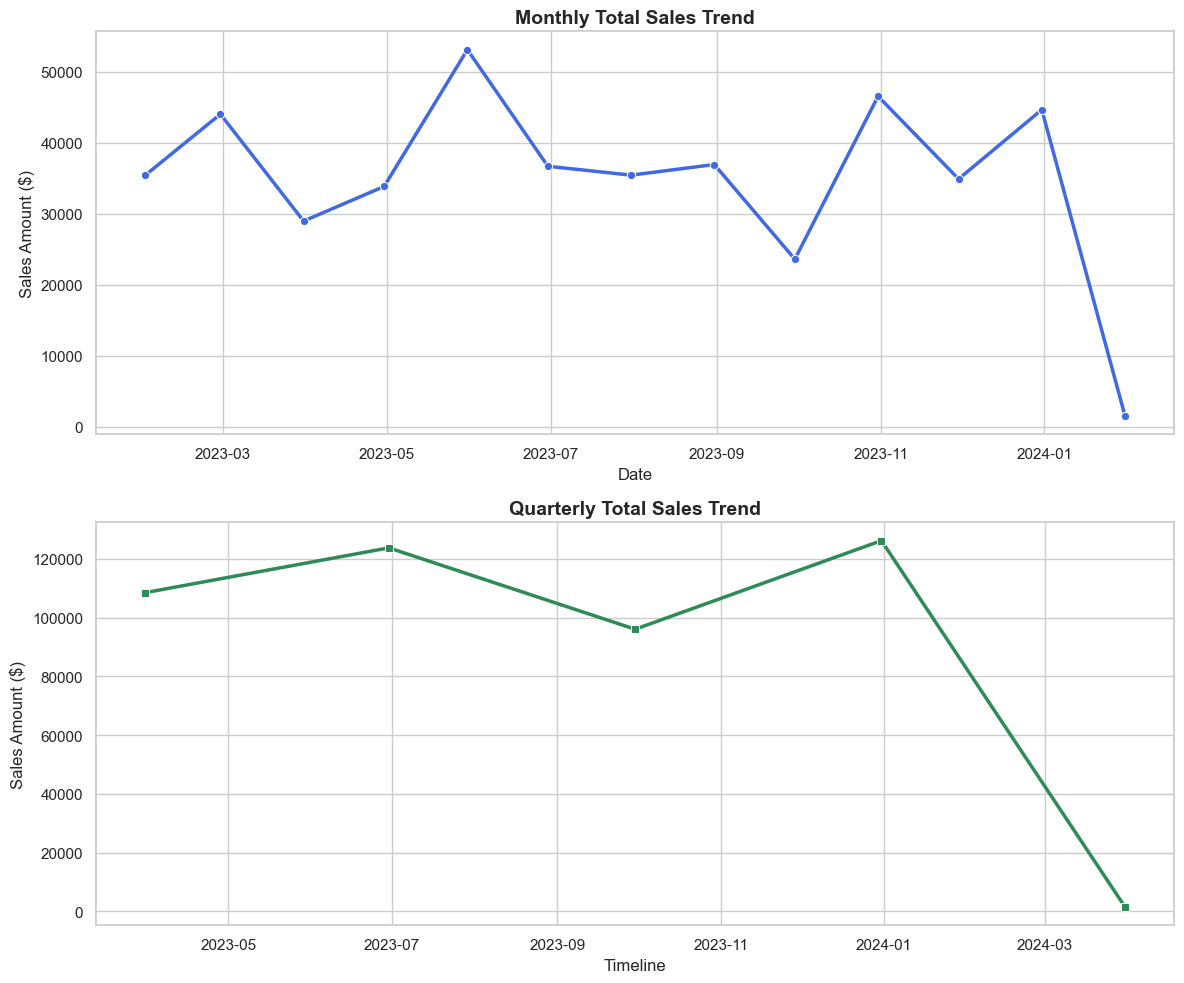

In [6]:
# Convert Date to datetime and set as index
df['Date'] = pd.to_datetime(df['Date'])
df_time = df.set_index('Date')

# Resample by Month and Quarter
monthly_sales = df_time['Total Amount'].resample('ME').sum()
quarterly_sales = df_time['Total Amount'].resample('QE').sum()

# Plotting trends
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

sns.lineplot(ax=axes[0], data=monthly_sales, marker='o', color='royalblue', linewidth=2.5)
axes[0].set_title('Monthly Total Sales Trend', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Sales Amount ($)')

sns.lineplot(ax=axes[1], data=quarterly_sales, marker='s', color='seagreen', linewidth=2.5)
axes[1].set_title('Quarterly Total Sales Trend', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Sales Amount ($)')
axes[1].set_xlabel('Timeline')

plt.tight_layout()
plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_5672\2201059797.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(ax=axes[0], data=df, x='Age_Group', palette='Blues_d', order=labels)


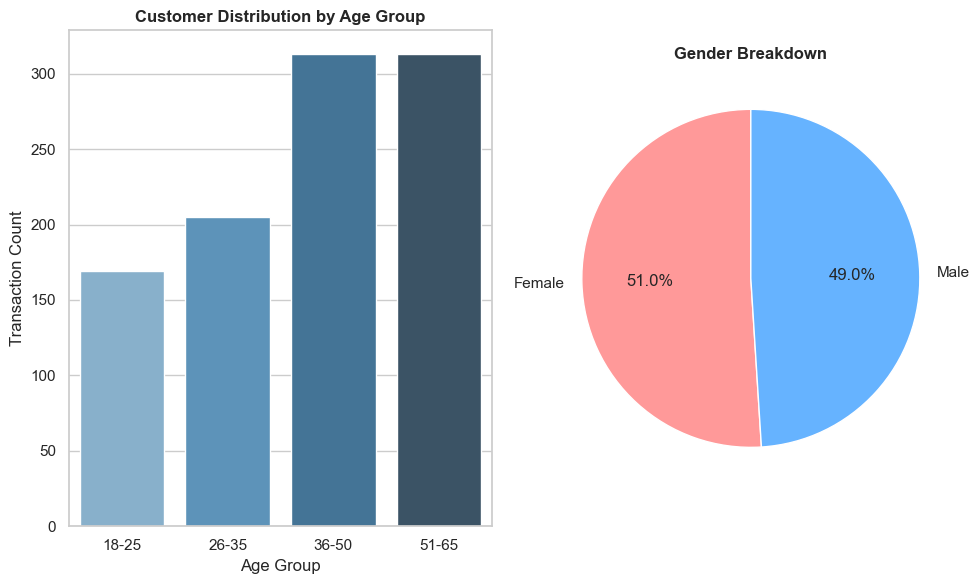

In [7]:
#Customer Demographics Analysis
# Age Group Segmentation
bins = [17, 25, 35, 50, 65]
labels = ['18-25', '26-35', '36-50', '51-65']
df['Age_Group'] = pd.cut(df['Age'], bins=bins, labels=labels)

fig, axes = plt.subplots(1, 2, figsize=(10, 6))

# Age Group Distribution
sns.countplot(ax=axes[0], data=df, x='Age_Group', palette='Blues_d', order=labels)
axes[0].set_title('Customer Distribution by Age Group', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Age Group')
axes[0].set_ylabel('Transaction Count')

# Gender Breakdown
gender_counts = df['Gender'].value_counts()
axes[1].pie(gender_counts, labels=gender_counts.index, autopct='%1.1f%%', startangle=90, colors=['#ff9999','#66b3ff'])
axes[1].set_title('Gender Breakdown', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


NameError: name 'avg_spend' is not defined

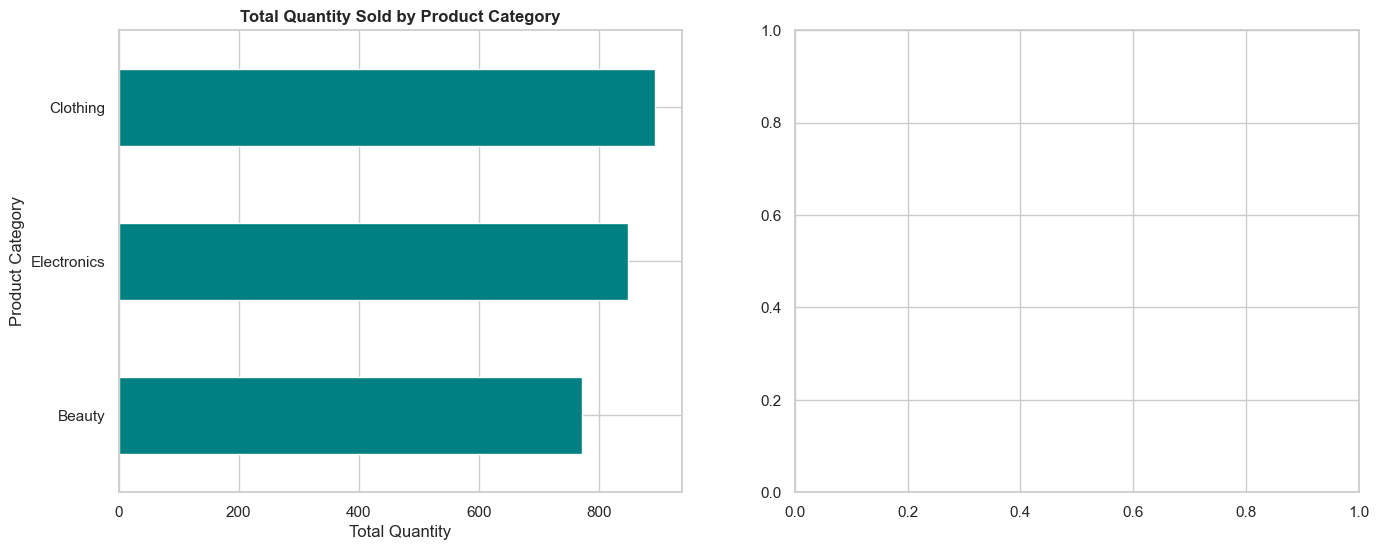

In [8]:
#Product Analysis
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Top Product Categories by Quantity Sold
top_categories_qty = df.groupby('Product Category')['Quantity'].sum().sort_values(ascending=True)
top_categories_qty.plot(ax=axes[0], kind='barh', color='teal')
axes[0].set_title('Total Quantity Sold by Product Category', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Total Quantity')

# Revenue by Product Category
category_revenue = df.groupby('Product Category')['Total Amount'].sum().sort_values(ascending=False)
sns.barplot(ax=axes[1], x=category_revenue.index, y=category_revenue.values,hue=avg_spend.index, palette='viridis')
axes[1].set_title('Total Revenue by Product Category', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Total Revenue ($)')
axes[1].set_xlabel('Product Category')

plt.tight_layout()
plt.show()

In [ ]:
#Correlation Matrix Heatmap
plt.figure(figsize=(8, 6))
correlation = df[numerical_cols].corr()

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, cbar=True)
plt.title('Correlation Matrix of Numerical Variables', fontsize=14, fontweight='bold')
plt.show()

In [ ]:
#Additional Insight Visualisation (Average Basket Size / Spend per Transaction by Category)
#Correlation Matrix Heatmap
plt.figure(figsize=(10, 6))
avg_spend = df.groupby('Product Category')['Total Amount'].mean().sort_values(ascending=False)

sns.barplot(x=avg_spend.index, y=avg_spend.values,hue=avg_spend.index, palette='magma',)
plt.title('Average Spend per Transaction by Product Category', fontsize=14, fontweight='bold')
plt.ylabel('Average Total Amount ($)')
plt.xlabel('Product Category')
plt.show()

In [ ]:
#Conclusion & Actionable Business Recommendations
#Markdown Cell (Conclusion):


#1. Prioritize High-Value Inventory Allocation: Since Electronics drives the highest average transaction values and overall revenue, ensure robust stock levels and premium placement for these items.

#2. Tailor Promotional Bundles for Volume Categories: Leverage the steady unit movement in Beauty and Clothing by introducing multi-item bundles or cross-category discounts to boost average order value.

#3. Omnichannel Engagement Across Demographics: Given the balanced gender breakdown and broad age distribution, marketing campaigns should maintain a broad appeal rather than hyper-targeting a narrow niche.